In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import LabelEncoder,OrdinalEncoder


sns.set(rc={'figure.figsize': [7, 7]}, font_scale=1.2)

In [94]:
df = pd.read_csv('car data.csv')
df

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [95]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [96]:
df.shape

(301, 9)

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [98]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [99]:
df.duplicated().sum()

np.int64(2)

In [100]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [101]:
df.select_dtypes(include='object').describe()

,Car_Name,Fuel_Type,Seller_Type,Transmission
count,301,301,301,301
unique,98,3,2,2
top,city,Petrol,Dealer,Manual
freq,26,239,195,261


In [102]:
def top_and_bottom_combined(data, col, n=5):
    top_counts =data[col].value_counts().head(n)

    bottom_counts= data[col].value_counts().tail(n)

    combined =pd.concat([top_counts, bottom_counts], axis=0)
    combined.columns=['Most Frequent', 'Least Frequent']

    return combined

for col in df.select_dtypes(include ='object'):

    print(f'{col} value counts:')

    print(top_and_bottom_combined(df, col))

    print('30 Unique values:', df[col].unique()[:30])
 

Car_Name value counts:
Car_Name
city                        26
corolla altis               16
verna                       14
fortuner                    11
brio                        10
Honda CB Trigger             1
Yamaha FZ S                  1
Bajaj Pulsar 135 LS          1
Activa 4g                    1
Bajaj Avenger Street 220     1
Name: count, dtype: int64
30 Unique values: ['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'Royal Enfield Thunder 500'
 'UM Renegade Mojave' 'KTM RC200' 'Bajaj Dominar 400'
 'Royal Enfield Classic 350']
Fuel_Type value counts:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64
30 Unique values: ['Petrol' 'Diesel' 'CNG']
Seller_Type value counts:
Seller_Type
Dealer        195
Indi

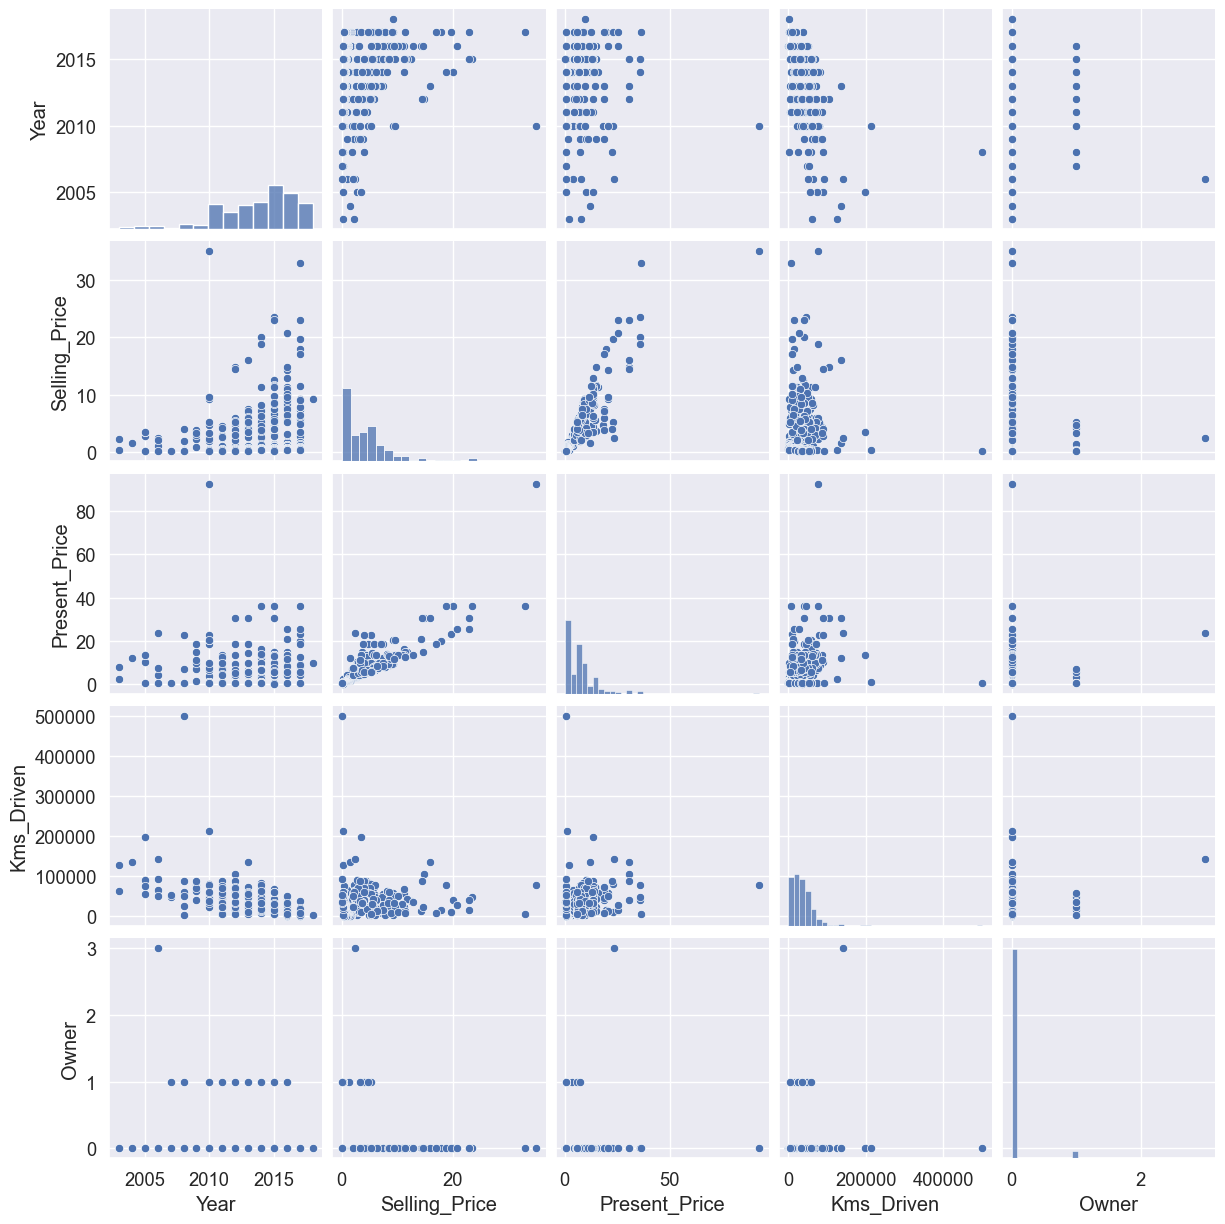

In [103]:
sns.pairplot(df)

<Axes: >

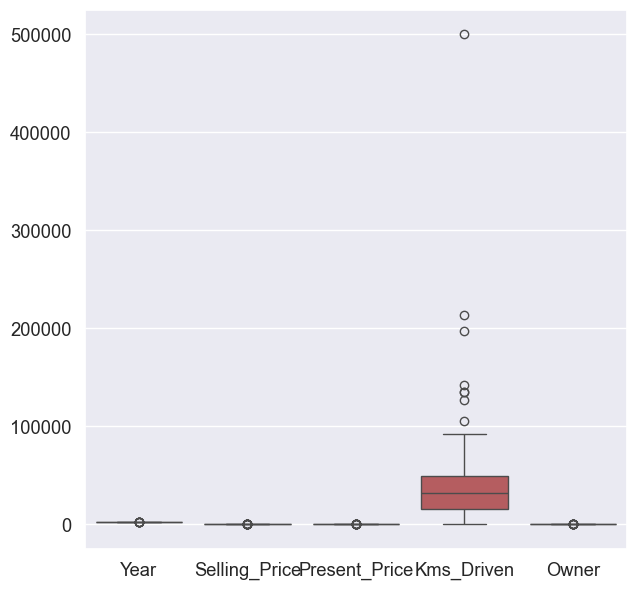

In [104]:
sns.boxplot(df)

<Axes: ylabel='Present_Price'>

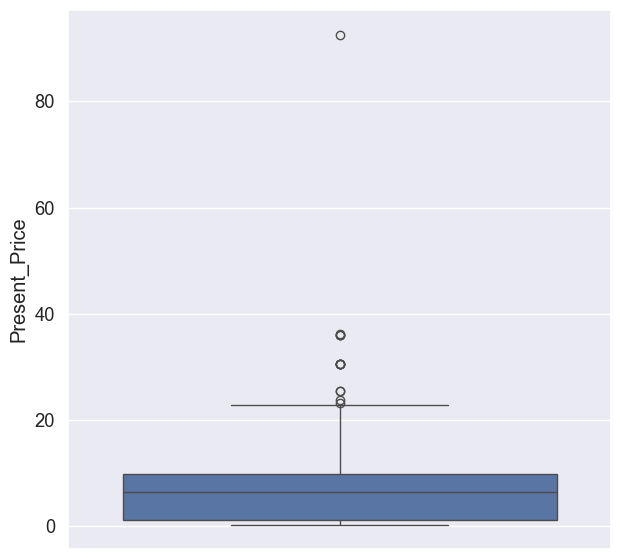

In [105]:
sns.boxplot(df['Present_Price'])

Clean Outliers

In [106]:
def clean_outliers(data,col):
    q1=data[col].quantile(0.25)
    q3=data[col].quantile(0.75)
    iqr= q3-q1

    lower_bound= q1 - 1.5*iqr
    upper_bound= q3 + 1.5*iqr
    data_no_outliers = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]
    return data_no_outliers

In [107]:
df = clean_outliers(df,'Present_Price')
df = clean_outliers(df,'Kms_Driven')


In [108]:
df.shape

(282, 9)

Cleaning

In [109]:
df.columns.str.lower().str.replace(' ' ,'_')
string_columns=list(df.dtypes[df.dtypes=='object'].index)
for col in string_columns:
    df[col]=df[col].str.lower().str.replace(' ' ,'_')
string_columns 

['Car_Name', 'Fuel_Type', 'Seller_Type', 'Transmission']

One Hot Encoding

In [110]:
one_hot_encoding = ['Transmission','Seller_Type','Fuel_Type']
df=pd.get_dummies(df,columns=one_hot_encoding, dtype=int)

Label Encoding

In [111]:
label_encoder=LabelEncoder()
label_encode_columns=['Car_Name']
for column in label_encode_columns:
    df[column] = label_encoder.fit_transform( df[column])

In [112]:
df

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Transmission_automatic,Transmission_manual,Seller_Type_dealer,Seller_Type_individual,Fuel_Type_cng,Fuel_Type_diesel,Fuel_Type_petrol
0,69,2014,3.35,5.59,27000,0,0,1,1,0,0,0,1
1,78,2013,4.75,9.54,43000,0,0,1,1,0,0,1,0
2,22,2017,7.25,9.85,6900,0,0,1,1,0,0,0,1
3,87,2011,2.85,4.15,5200,0,0,1,1,0,0,0,1
4,77,2014,4.60,6.87,42450,0,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,23,2016,9.50,11.60,33988,0,0,1,1,0,0,1,0
297,21,2015,4.00,5.90,60000,0,0,1,1,0,0,0,1
298,23,2009,3.35,11.00,87934,0,0,1,1,0,0,0,1
299,23,2017,11.50,12.50,9000,0,0,1,1,0,0,1,0


In [113]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Transmission_automatic,Transmission_manual,Seller_Type_dealer,Seller_Type_individual,Fuel_Type_cng,Fuel_Type_diesel,Fuel_Type_petrol
0,69,2014,3.35,5.59,27000,0,0,1,1,0,0,0,1
1,78,2013,4.75,9.54,43000,0,0,1,1,0,0,1,0
2,22,2017,7.25,9.85,6900,0,0,1,1,0,0,0,1
3,87,2011,2.85,4.15,5200,0,0,1,1,0,0,0,1
4,77,2014,4.60,6.87,42450,0,0,1,1,0,0,1,0


<Axes: >

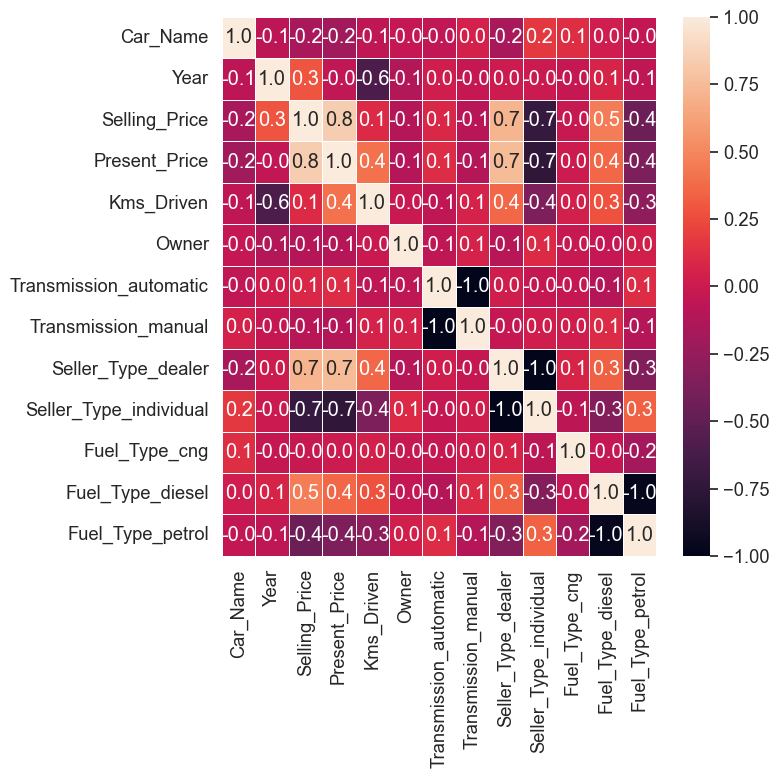

In [114]:
sns.heatmap(df.corr(),annot=True,fmt='.1f',linewidth=0.5)

Training

In [115]:
x=df.drop('Present_Price',axis=1)
y=df.Present_Price

In [116]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3,random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5,random_state=42)

In [117]:
print(len(x_train))
print(len(x_val))
print(len(x_test))

197
42
43


In [118]:
from sklearn.preprocessing import StandardScaler
numerical_columns=['Car_Name','Year']
scaler=StandardScaler()
x_train[numerical_columns]=scaler.fit_transform(x_train[numerical_columns])
x_val[numerical_columns]=scaler.transform(x_val[numerical_columns])
x_test[numerical_columns]=scaler.fit_transform(x_test[numerical_columns])

In [119]:
lr = LinearRegression()
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [120]:
y_val_pred = lr.predict(x_val)


mse = mean_squared_error(y_val,y_val_pred)
rmse=mse**0.5
r2=r2_score(y_val,y_val_pred)

In [121]:
lr.score(x_train, y_train)

0.8442441564879889

In [122]:
lr.score(x_test, y_test)

0.862300501292781

In [123]:
r2

0.8011381926585285

In [124]:
rmse

2.46299942963061

In [125]:
rf=RandomForestRegressor()
rf.fit(x_train,y_train)
y_val_pred=rf.predict(x_val)
mse = mean_squared_error(y_val,y_val_pred)
rmse=mse**0.5
r2=r2_score(y_val,y_val_pred)

In [126]:
r2

0.9081470974783605

In [127]:
rf.score(x_test, y_test)

0.8524952617884145

In [128]:
rmse

1.6739214031948493

In [129]:
model = XGBRegressor()
model.fit(x_train,y_train)
y_val_pred=model.predict(x_val)
mse = mean_squared_error(y_val,y_val_pred)
rmse=mse**0.5
r2=r2_score(y_val,y_val_pred)

In [130]:
r2

0.9456613989242462

In [131]:
rmse

1.2874869832773992

In [132]:
df.head(1)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Transmission_automatic,Transmission_manual,Seller_Type_dealer,Seller_Type_individual,Fuel_Type_cng,Fuel_Type_diesel,Fuel_Type_petrol
0,69,2014,3.35,5.59,27000,0,0,1,1,0,0,0,1


In [133]:
df['Car_Name'] = label_encoder.inverse_transform(df['Car_Name'])
print(df['Car_Name'].head())

0       ritz
1        sx4
2       ciaz
3    wagon_r
4      swift
Name: Car_Name, dtype: object


In [134]:

target_features = ['Fuel_Type', 'Transmission', 'Seller_Type']

for feature in target_features:
   
    encoded_cols = [col for col in df.columns if col.startswith(feature + '_')]
    
    if encoded_cols:
        df[feature] = df[encoded_cols].idxmax(axis=1).str.replace(feature + '_', '')
        
        df.drop(columns=encoded_cols, inplace=True)
print(df[target_features].head())

  Fuel_Type Transmission Seller_Type
0    petrol       manual      dealer
1    diesel       manual      dealer
2    petrol       manual      dealer
3    petrol       manual      dealer
4    diesel       manual      dealer


In [135]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type,Transmission,Seller_Type
0,ritz,2014,3.35,5.59,27000,0,petrol,manual,dealer
1,sx4,2013,4.75,9.54,43000,0,diesel,manual,dealer
2,ciaz,2017,7.25,9.85,6900,0,petrol,manual,dealer
3,wagon_r,2011,2.85,4.15,5200,0,petrol,manual,dealer
4,swift,2014,4.60,6.87,42450,0,diesel,manual,dealer


In [136]:
new_car_text = {'Car_Name': 'ritz','Year': 2016, 'Selling_Price': 3.3, 'Kms_Driven': 27000,'Fuel_Type': 'diesel','Seller_Type': 'Dealer',
                'Transmission': 'Manual', 'Owner': 0}

new_car_df = pd.DataFrame([new_car_text])

new_car_df['Car_Name'] = label_encoder.transform(new_car_df['Car_Name'])

new_car_encoded = pd.get_dummies(new_car_df)

model_columns = rf.feature_names_in_  # دي بتجيب أسماء الأعمدة اللي الموديل محتاجها
new_car_final = new_car_encoded.reindex(columns=model_columns, fill_value=0)

prediction = rf.predict(new_car_final)

print(f"Predict Price: {prediction[0]*1000 :.2f}",'$')

Predict Price: 6276.20 $


In [137]:
import joblib
joblib.load('rf_model.pkl')
joblib.dump(rf, "rf_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")


['label_encoder.pkl']

In [ ]:
import pandas as pd
from flask import Flask, request, render_template_string
from sklearn.preprocessing import LabelEncoder

app = Flask(__name__)

# تجهيز الـ Encoder والبيانات
df_original = pd.read_csv('car data.csv') 
le = LabelEncoder()
le.fit(df_original['Car_Name'])

# واجهة المستخدم بالإنجليزية
html_form = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Car Price Prediction</title>
    <style>
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; margin: 40px; background-color: #f0f2f5; }
        .container { background: white; padding: 30px; border-radius: 15px; max-width: 500px; margin: auto; box-shadow: 0 4px 15px rgba(0,0,0,0.1); }
        h2 { text-align: center; color: #333; }
        label { font-weight: bold; display: block; margin-top: 10px; color: #555; }
        input, select { width: 100%; padding: 12px; margin: 8px 0; border: 1px solid #ddd; border-radius: 8px; box-sizing: border-box; }
        button { width: 100%; padding: 12px; background-color: #007bff; color: white; border: none; border-radius: 8px; cursor: pointer; font-size: 16px; margin-top: 20px; }
        button:hover { background-color: #0056b3; }
        .result { background: #e7f3ff; padding: 20px; border-radius: 10px; margin-top: 25px; text-align: center; border: 1px solid #b3d7ff; }
        .result h3 { margin: 0; color: #004085; }
    </style>
</head>
<body>
    <div class="container">
        <h2>🚗🚗 Car Price Predictor</h2>
        <form method="POST">
            <label>Car Name</label>
            <input type="text" name="Car_Name" placeholder="e.g. ritz" required>
            
            <label>Manufacturing Year</label>
            <input type="number" name="Year" placeholder="e.g. 2015" required>
            
            <label>Present Price (in Lakhs)</label>
            <input type="number" step="0.01" name="Present_Price" placeholder="e.g. 5.59" required>
            
            <label>Kms Driven</label>
            <input type="number" name="Kms_Driven" placeholder="e.g. 27000" required>
            
            <label>Fuel Type</label>
            <select name="Fuel_Type">
                <option value="Petrol">Petrol</option>
                <option value="Diesel">Diesel</option>
                <option value="CNG">CNG</option>
            </select>
            
            <label>Seller Type</label>
            <select name="Seller_Type">
                <option value="Dealer">Dealer</option>
                <option value="Individual">Individual</option>
            </select>
            
            <label>Transmission</label>
            <select name="Transmission">
                <option value="Manual">Manual</option>
                <option value="Automatic">Automatic</option>
            </select>
            
            <label>Past Owners</label>
            <input type="number" name="Owner" value="0">
            
            <button type="submit">Predict Price</button>
        </form>

        {% if prediction %}
            <div class="result">
                <h3>Estimated Selling Price: {{ prediction }}$</h3>
            </div>
        {% endif %}
    </div>
</body>
</html>
"""

@app.route('/', methods=['GET', 'POST'])
def index():
    prediction_text = None
    if request.method == 'POST':
        try:
            data = {
                'Car_Name': request.form['Car_Name'],
                'Year': int(request.form['Year']),
                'Present_Price': float(request.form['Present_Price']),
                'Kms_Driven': int(request.form['Kms_Driven']),
                'Fuel_Type': request.form['Fuel_Type'],
                'Seller_Type': request.form['Seller_Type'],
                'Transmission': request.form['Transmission'],
                'Owner': int(request.form['Owner'])
            }

            df_new = pd.DataFrame([data])

            df_new['Car_Name'] = label_encoder.transform(df_new['Car_Name'])
           # df_new['Car_Name'] = le.transform(df_new['Car_Name'])
            df_encoded = pd.get_dummies(df_new)
            
            model_columns = rf.feature_names_in_
            df_final = df_encoded.reindex(columns=model_columns, fill_value=0)
            res = rf.predict(df_final)
            print(f"Predict Price: {prediction[0]*1000 :.2f}",'$')
            # ملحوظة: السعر في الداتا الأصلية غالباً بالـ Lakhs (100,000)
            final_val = res[0]
            prediction_text = f"{final_val*10000:,.2f}"
        except Exception as e:
            prediction_text = f"Error: {str(e)}"
           

    return render_template_string(html_form, prediction=prediction_text)

if __name__ == '__main__' :
    app.run(port=5003, debug=True, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5003
Press CTRL+C to quit
127.0.0.1 - - [10/May/2026 12:06:03] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [10/May/2026 12:06:12] "POST / HTTP/1.1" 200 -


Predict Price: 6276.20 $
